# IT Service Desk RAG Assistant
Projek Tugas Besar — AI Engineer Track

**Stack:** Qwen2.5-7B-Instruct (4-bit) - multilingual-e5-base - ChromaDB - LlamaIndex - Gradio - RAGAS

**Runtime:** Google Colab GPU T4

Arsitektur: Ingestion PDF (bersih + OCR slide) → Vector Store → Retrieval → Guardrail (threshold terkalibrasi) → Generation (LLM) → Ticket Classification → Logging → UI Gradio → Evaluasi.


## 1. Setup & Dependensi

In [1]:
!pip install -q llama-index llama-index-embeddings-huggingface llama-index-llms-huggingface \
    llama-index-vector-stores-chroma chromadb transformers accelerate bitsandbytes sentencepiece \
    pymupdf gradio pytesseract pdf2image datasets \
    'ragas==0.1.21' 'langchain==0.2.16' 'langchain-community==0.2.16' 'langchain-huggingface<0.1'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 112.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.5/174.5 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 103.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 128.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

### Install Dependensi Sistem untuk OCR

In [2]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind poppler-utils


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../libpoppler-private-dev_24.02.0-1ubuntu9.10_amd64.deb ...
Unpacking libpoppler-private-dev:amd64 (24.02.0-1ubuntu9.10) over (24.02.0-1ubuntu9.9) ...
Preparing to unpack .../libpoppler-dev_24.02.0-1ubuntu9.10_amd64.deb ...
Unpacking libpoppler-dev:amd64 (24.02.0-1ubuntu9.10) over (24.02.0-1ubuntu9.9) ...
Preparing to unpack .../libpoppler134_24.02.0-1ubuntu9.10_amd64.deb ...
Unpacking libpoppler134:amd64 (24.02.0-1ubuntu9.10) over (24.02.0-1ubuntu9.9) ...
Selecting previously unselected package poppler-utils.
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.10_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.10) ...
Selecting previously unselected package tesseract-ocr-ind.
Preparing to unpack 

Restart Otomatis 1x

In [3]:
import os
FLAG = '/content/.restart_done_after_install'
if not os.path.exists(FLAG):
    open(FLAG, 'w').write('ok')
    print('Install selesai. Runtime RESTART OTOMATIS sekarang (normal).')
    print('Setelah restart: lanjutkan dari cell Cek GPU, tanpa mengulang cell install.')
    import IPython
    IPython.get_ipython().kernel.do_shutdown(True)
else:
    print('Restart pasca-install sudah dilakukan. Lanjut ke cell berikutnya.')


Install selesai. Runtime RESTART OTOMATIS sekarang (normal).
Setelah restart: lanjutkan dari cell Cek GPU, tanpa mengulang cell install.


## 2. Cek GPU & Konfigurasi Dasar

In [1]:
import torch
print('GPU tersedia:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nama GPU:', torch.cuda.get_device_name(0))
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


GPU tersedia: True
Nama GPU: Tesla T4
VRAM: 15.6 GB


In [2]:
import os, re, time, random, collections, csv, hashlib
from datetime import datetime
import numpy as np
import pandas as pd

# ---------------- Path ----------------
BASE_DIR        = '/content'
PDF_DIR         = f'{BASE_DIR}/knowledge_base'
CHROMA_DIR      = f'{BASE_DIR}/chroma_db'
COLLECTION_NAME = 'it_service_desk'
LOG_FILE        = f'{BASE_DIR}/ticket_log.csv'
TESTSET_PATH    = f'{BASE_DIR}/test_set_draft.csv'

# ---------------- Hyperparameter RAG (knob untuk eksperimen/ablation) ----------------
CHUNK_SIZE           = 400    # token per chunk
CHUNK_OVERLAP        = 50
PAGES_PER_DOC        = 1      # gabung N halaman buku jadi 1 dokumen
TOP_K                = 4      # jumlah chunk UNIK yang dikirim ke LLM
FETCH_K              = 8      # ambil kandidat lebih banyak, buang duplikat, lalu ambil TOP_K
SIMILARITY_THRESHOLD = globals().get('SIMILARITY_THRESHOLD', 0.80)   # jangan timpa hasil kalibrasi
SEED                 = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- Generasi jawaban (kunci faithfulness) ----------------
MAX_NEW_TOKENS          = 320    # jawaban ringkas
USE_ANSWERABILITY_CHECK = True   # LLM boleh menjawab TIDAK_DITEMUKAN -> dieskalasi (benteng ke-2 guardrail)
VERIFY_PASS             = False  # eksperimen: 2nd pass yang memangkas klaim tak didukung konteks (2x latensi)

CATEGORIES = ['Hardware', 'Software', 'Network', 'Hosting', 'Access/Akun', 'Lainnya']

# ---------------- Peta sumber -> kategori knowledge base ----------------
SOURCES = {
    'Troubleshooting.pdf':                    {'category': 'Network',           'kind': 'book'},
    'Buku-Troubleshooting-Komputer-Full.pdf': {'category': 'Hardware/Software', 'kind': 'book'},
    '13 Hosting Website.pdf':                 {'category': 'Hosting',           'kind': 'slides'},
    'Dokumen Knowledge Base IT Service Desk.pdf': {'category': 'SOP Internal',  'kind': 'book'},
    'Knowledge_Base_IT_Service_Desk_RAG.pdf':     {'category': 'SOP Internal',  'kind': 'book'},
}
DEFAULT_SOURCE = {'category': 'Lainnya', 'kind': 'book'}

def canon_name(fname):
    """'Troubleshooting (3).pdf' -> 'Troubleshooting.pdf'"""
    if not isinstance(fname, str):
        return ''
    return re.sub(r'\s*\(\d+\)(?=\.[^.]+$)', '', fname)

def _norm(s):
    return re.sub(r'[\s_\-]+', '', s.lower())
SOURCES_NORM = {_norm(k): v for k, v in SOURCES.items()}
def get_source_cfg(fname):
    return SOURCES_NORM.get(_norm(canon_name(fname)), DEFAULT_SOURCE)

def file_sha1(path):
    h = hashlib.sha1()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

def dedupe_pdf_dir(pdf_dir=None, verbose=True):
    """Hapus PDF berisi sama (hash identik); pertahankan yang bernama kanonik; ganti nama '(n)' jika perlu."""
    pdf_dir = pdf_dir or PDF_DIR
    groups = collections.defaultdict(list)
    for f in sorted(os.listdir(pdf_dir)):
        if f.lower().endswith('.pdf'):
            groups[file_sha1(os.path.join(pdf_dir, f))].append(f)
    removed = []
    for names in groups.values():
        names.sort(key=lambda n: (n != canon_name(n), len(n), n))
        keep = names[0]
        for dup in names[1:]:
            os.remove(os.path.join(pdf_dir, dup)); removed.append(dup)
        target = canon_name(keep)
        if target != keep and not os.path.exists(os.path.join(pdf_dir, target)):
            os.rename(os.path.join(pdf_dir, keep), os.path.join(pdf_dir, target))
    final = sorted(os.listdir(pdf_dir))
    if verbose:
        print(f'Duplikat dihapus ({len(removed)}):', removed)
        print('File unik di knowledge base:', final)
    return final

print('Konfigurasi dimuat.')

Konfigurasi dimuat.


## 3. Load Embedding Model

In [3]:
from llama_index.embeddings.huggingface import HuggingFaceEmbedding

embed_model = HuggingFaceEmbedding(
    model_name='intfloat/multilingual-e5-base',
    query_instruction='query: ',
    text_instruction='passage: ',
    device='cuda' if torch.cuda.is_available() else 'cpu'
)
print('Embedding model siap.')


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Embedding model siap.


## 4. Load LLM (Qwen2.5-7B-Instruct, 4-bit)

In [4]:
from transformers import AutoTokenizer, BitsAndBytesConfig
from llama_index.llms.huggingface import HuggingFaceLLM

MODEL_NAME = 'Qwen/Qwen2.5-7B-Instruct'

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True,
)

system_prompt = (
    'Kamu adalah asisten IT Service Desk. Jawab HANYA berdasarkan konteks dokumen '
    'yang diberikan. Jika informasi tidak ada dalam konteks, katakan dengan jujur '
    'bahwa kamu tidak menemukan informasinya dan sarankan eskalasi ke agent manusia. '
    'Jangan mengarang jawaban. '
    'Jawab dengan ringkas dan jelas.'
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def messages_to_prompt(messages):
    msgs = [{'role': m.role.value, 'content': m.content} for m in messages]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def completion_to_prompt(completion):
    msgs = [{'role': 'system', 'content': system_prompt},
            {'role': 'user', 'content': completion}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

llm = HuggingFaceLLM(
    model_name=MODEL_NAME,
    tokenizer_name=MODEL_NAME,
    context_window=8192,
    max_new_tokens=MAX_NEW_TOKENS,
    system_prompt=system_prompt,
    messages_to_prompt=messages_to_prompt,
    completion_to_prompt=completion_to_prompt,
    model_kwargs={'quantization_config': quant_config},
    tokenizer_kwargs={'trust_remote_code': True},
    generate_kwargs={'do_sample': False},
    device_map='auto',
)
print('LLM siap.')

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

LLM siap.


## 5. Set Konfigurasi Global LlamaIndex

In [5]:
from llama_index.core import Settings

Settings.llm = llm
Settings.embed_model = embed_model
Settings.chunk_size = CHUNK_SIZE
Settings.chunk_overlap = CHUNK_OVERLAP


### Generate_text (chat template + greedy)

In [6]:
import torch

STOP_MARKERS = ['---------------------', '\nJawaban:', '\nPertanyaan:', '<|im_end|>', '<|endoftext|>', '<|im_start|>']

def clean_generation(text):
    cut = len(text)
    for mk in STOP_MARKERS:
        p = text.find(mk)
        if p != -1:
            cut = min(cut, p)
    return text[:cut].strip()

def generate_text(user_prompt, system=None, max_new_tokens=None):
    max_new_tokens = max_new_tokens or MAX_NEW_TOKENS
    msgs = ([{'role': 'system', 'content': system}] if system else []) + [{'role': 'user', 'content': user_prompt}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors='pt').to(llm._model.device)
    with torch.no_grad():
        out = llm._model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                  repetition_penalty=1.0, pad_token_id=tokenizer.eos_token_id)
    gen = out[0][inputs['input_ids'].shape[1]:]
    return clean_generation(tokenizer.decode(gen, skip_special_tokens=True))

print(generate_text('Sebutkan satu fungsi utama modem dalam satu kalimat.', max_new_tokens=60))

Fungsi utama modem adalah mengubah sinyal digital dari komputer menjadi sinyal analog untuk dapat diproses oleh jaringan telepon, dan sebaliknya.


## 6. Upload Dokumen PDF (Knowledge Base)

In [7]:
from google.colab import files

os.makedirs(PDF_DIR, exist_ok=True)
print('Upload file PDF knowledge base:')
uploaded = files.upload()
for fname in uploaded.keys():
    os.replace(fname, os.path.join(PDF_DIR, fname))

final_files = dedupe_pdf_dir(PDF_DIR)
unknown = [f for f in final_files if get_source_cfg(f) is DEFAULT_SOURCE]
if unknown:
    print('PERINGATAN: file berikut belum ada di SOURCES (kategori default "Lainnya"):', unknown)

Upload file PDF knowledge base:


Saving Knowledge_Base_IT_Service_Desk_RAG.pdf to Knowledge_Base_IT_Service_Desk_RAG.pdf
Saving Dokumen Knowledge Base IT Service Desk.pdf to Dokumen Knowledge Base IT Service Desk.pdf
Saving 13 Hosting Website.pdf to 13 Hosting Website.pdf
Saving Troubleshooting.pdf to Troubleshooting.pdf
Saving Buku-Troubleshooting-Komputer-Full.pdf to Buku-Troubleshooting-Komputer-Full.pdf
Duplikat dihapus (0): []
File unik di knowledge base: ['13 Hosting Website.pdf', 'Buku-Troubleshooting-Komputer-Full.pdf', 'Dokumen Knowledge Base IT Service Desk.pdf', 'Knowledge_Base_IT_Service_Desk_RAG.pdf', 'Troubleshooting.pdf']


### Bersihkan duplikat PDF (tanpa upload ulang)

In [8]:
print('Sebelum:', sorted(os.listdir(PDF_DIR)))
final_files = dedupe_pdf_dir(PDF_DIR)
unknown = [f for f in final_files if get_source_cfg(f) is DEFAULT_SOURCE]
if unknown:
    print('PERINGATAN: file berikut belum ada di SOURCES (kategori default "Lainnya"):', unknown)

Sebelum: ['13 Hosting Website.pdf', 'Buku-Troubleshooting-Komputer-Full.pdf', 'Dokumen Knowledge Base IT Service Desk.pdf', 'Knowledge_Base_IT_Service_Desk_RAG.pdf', 'Troubleshooting.pdf']
Duplikat dihapus (0): []
File unik di knowledge base: ['13 Hosting Website.pdf', 'Buku-Troubleshooting-Komputer-Full.pdf', 'Dokumen Knowledge Base IT Service Desk.pdf', 'Knowledge_Base_IT_Service_Desk_RAG.pdf', 'Troubleshooting.pdf']


## 7. Parsing PDF

In [9]:
import fitz  # PyMuPDF
import pytesseract
from pdf2image import convert_from_path
from llama_index.core import Document

OCR_DPI = 200         # resolusi render halaman
try:
    OCR_LANG = 'ind+eng' if 'ind' in pytesseract.get_languages() else 'eng'
except Exception:
    OCR_LANG = 'eng'
print('Bahasa OCR:', OCR_LANG)

SKIP_TITLES = re.compile(r'^\s*(DAFTAR\s+ISI|DAFTAR\s+GAMBAR|DAFTAR\s+TABEL|KATA\s+PENGANTAR|PRAKATA)\s*$', re.I | re.M)
BIB_TITLE   = re.compile(r'^\s*(DAFTAR\s+PUSTAKA|REFERENSI|TENTANG\s+PENULIS|INDEKS)\s*$', re.I | re.M)
CHAPTER     = re.compile(r'^\s*BAB\s+(I|1)\.?\s*$', re.I | re.M)
COPYRIGHT   = re.compile(r'(ISBN|Hak\s+Cipta|All\s+Rights?\s+Reserved|Dilarang\s+(keras\s+)?memperbanyak)', re.I)

def looks_like_toc(text):
    lines = [l for l in text.splitlines() if l.strip()]
    if len(lines) < 5:
        return False
    dotted = sum(1 for l in lines if re.search(r'(\.{3,}|\s{2,})\d+\s*$', l) or re.search(r'\.{5,}', l))
    return dotted / len(lines) > 0.3

def sanitize(text):
    text = re.sub(r'\?utm_source=\S+', '', text)
    return re.sub(r"(?i)(password\s*[:=]?\s*)(['\"])[^'\"]*\2", r"\1\2<PASSWORD_KUAT>\2", text)

def clean_book_pages(raw_pages):
    n = len(raw_pages)
    start = next((i for i, t in enumerate(raw_pages)
                  if CHAPTER.search(t) and not looks_like_toc(t) and not SKIP_TITLES.search(t)), 0)
    end = next((i for i in range(start, n)
                if BIB_TITLE.search(raw_pages[i]) and len(raw_pages[i].strip()) < 4000), n)
    keep = [i for i in range(start, end)
            if not looks_like_toc(raw_pages[i]) and not SKIP_TITLES.search(raw_pages[i])
            and not COPYRIGHT.search(raw_pages[i])]
    freq = collections.Counter()
    for i in keep:
        for l in {x.strip() for x in raw_pages[i].splitlines() if x.strip() and len(x.strip()) < 80}:
            freq[l] += 1

    boiler = set()
    if len(keep) >= 8:
        thr = max(3, 0.25 * len(keep))
        boiler = {l for l, c in freq.items() if c >= thr}
    out = []
    for i in keep:
        lines = [l for l in raw_pages[i].splitlines()
                 if l.strip() and l.strip() not in boiler and not re.fullmatch(r'\s*\d{1,3}\s*', l)]
        if lines:
            out.append((i + 1, '\n'.join(lines).strip()))
    return out

def _alnum_words(s):
    return re.findall(r'[a-z0-9]+', s.lower())

CODE_HINT = re.compile(r"[./:(){};_$\\]|^\s*(cd|sudo|git|npm|pip|node|ls|mkdir|psql|create|grant|select|insert|const|let|var|require)\b", re.I)

def extract_slides(pdf_path, raw_pages):
    merged = []
    for i, text in enumerate(raw_pages):
        img = convert_from_path(pdf_path, dpi=OCR_DPI, first_page=i + 1, last_page=i + 1)[0]
        ocr = pytesseract.image_to_string(img, lang=OCR_LANG)
        known = set(_alnum_words(text))
        extra = []
        for l in ocr.splitlines():
            l = l.strip()
            words = _alnum_words(l)
            if not words or set(words) <= known:
                continue
            if CODE_HINT.search(l):
                extra.append(l)
        merged.append(f'[Slide {i + 1}]\n{text.strip()}\n' + '\n'.join(extra))
    return '\n\n'.join(merged)

def make_doc(text, meta):
    return Document(text=text, metadata=meta,
                    excluded_embed_metadata_keys=list(meta), excluded_llm_metadata_keys=list(meta))

documents = []
seen_hash = {}
for fname in sorted(os.listdir(PDF_DIR)):
    if not fname.lower().endswith('.pdf'):
        continue
    fpath = os.path.join(PDF_DIR, fname)
    h = file_sha1(fpath)
    if h in seen_hash:
        print(f'  [LEWATI] {fname} identik dengan {seen_hash[h]}')
        continue
    seen_hash[h] = fname
    cname = canon_name(fname)
    cfg = get_source_cfg(fname)
    if cfg is DEFAULT_SOURCE:
        print(f'  [INFO] {cname} tidak ada di SOURCES -> kategori Lainnya, kind book')
    pdf = fitz.open(fpath)
    raw = [p.get_text() for p in pdf]
    pdf.close()
    base = {'file_name': cname, 'category': cfg['category']}

    if cfg['kind'] == 'slides':
        text = sanitize(extract_slides(fpath, raw))
        documents.append(make_doc(text, {**base, 'page_number': f'1-{len(raw)}', 'page_start': 1,
                                         'page_end': len(raw), 'extraction_method': 'text+ocr'}))
        print(f'{cname}: {len(raw)} slide -> 1 dokumen (teks + OCR), {len(text):,} karakter')
    else:
        pages = clean_book_pages(raw)
        for g in range(0, len(pages), PAGES_PER_DOC):
            grp = pages[g:g + PAGES_PER_DOC]
            ps, pe = grp[0][0], grp[-1][0]
            text = sanitize('\n\n'.join(t for _, t in grp))
            documents.append(make_doc(text, {**base, 'page_number': ps if ps == pe else f'{ps}-{pe}',
                                             'page_start': ps, 'page_end': pe, 'extraction_method': 'text'}))
        print(f'{cname}: {len(raw)} halaman -> {len(pages)} halaman isi dipertahankan')

print(f'\nTotal unit dokumen: {len(documents)}')
print('Per kategori:', dict(collections.Counter(d.metadata["category"] for d in documents)))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Bahasa OCR: ind+eng
13 Hosting Website.pdf: 12 slide -> 1 dokumen (teks + OCR), 2,905 karakter
Buku-Troubleshooting-Komputer-Full.pdf: 138 halaman -> 121 halaman isi dipertahankan
Dokumen Knowledge Base IT Service Desk.pdf: 3 halaman -> 3 halaman isi dipertahankan
Knowledge_Base_IT_Service_Desk_RAG.pdf: 6 halaman -> 6 halaman isi dipertahankan
Troubleshooting.pdf: 122 halaman -> 98 halaman isi dipertahankan

Total unit dokumen: 229
Per kategori: {'Hosting': 1, 'Hardware/Software': 121, 'SOP Internal': 9, 'Network': 98}


kode dari slide hosting terbaca OCR dan password sudah diganti placeholder.

In [10]:
slide_docs = [d for d in documents if d.metadata.get('extraction_method') == 'text+ocr']
for d in slide_docs[:1]:
    print(d.text[:3500])

[Slide 1]
Yunia Ikawati
Teknik Informatika-PENS
Workshop Pemrograman WEB
Hosting Website
DO O feu) BERDAMPAK NOVAS)

[Slide 2]
Hosting dan 
Domain
Apa Itu Hosting dan Domain?
• Hosting: Tempat menyimpan file website agar bisa 
diakses melalui internet.
• Domain: Alamat website yang digunakan untuk 
mengakses hosting (contoh: 
www.namadomain.com).
Website yang dibuat di komputer tidak bisa diakses 
publik jika belum diupload ke hosting.


[Slide 3]
Hosting Website
• Hosting adalah layanan untuk menyimpan aplikasi web (file HTML, 
CSS, JavaScript, backend, dll) agar dapat diakses melalui internet.
• Komponen utama hosting:
• Server → komputer yang menyimpan dan menjalankan aplikasi
• Domain → alamat website (contoh: www.namamu.com)
• Database → tempat penyimpanan data (misalnya PostgreSQL)
Contoh:
 
Hosting = rumah 
 
Domain = alamat rumah 
Contoh domain:
•
kampus.ac.id
•
belajarweb.com


[Slide 4]
Langkah Hosting Website
1. Menyiapkan Website
Sebelum dihosting, pastikan website sudah si

## 8. Chunking + Vector Index (ChromaDB, cosine)

In [11]:
import chromadb
from llama_index.vector_stores.chroma import ChromaVectorStore
from llama_index.core import VectorStoreIndex, StorageContext
from llama_index.core.node_parser import SentenceSplitter

assert len(documents) > 0, (
    'documents kosong -- jalankan ulang sel parsing PDF dulu sebelum sel ini, '
    'dan pastikan tercetak "Total unit dokumen: <angka > 0>" di outputnya.'
)

chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)

existing = [c if isinstance(c, str) else c.name for c in chroma_client.list_collections()]
if COLLECTION_NAME in existing:
    chroma_client.delete_collection(COLLECTION_NAME)
    print(f'Collection lama "{COLLECTION_NAME}" dihapus.')

chroma_collection = chroma_client.create_collection(COLLECTION_NAME, metadata={'hnsw:space': 'cosine'})
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)
storage_context = StorageContext.from_defaults(vector_store=vector_store)

index = VectorStoreIndex.from_documents(
    documents,
    storage_context=storage_context,
    transformations=[SentenceSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP)],
    store_nodes_override=True,
    show_progress=True,
)

n_nodes = len(index.docstore.docs)
cats = collections.Counter(n.metadata.get('category') for n in index.docstore.docs.values())
print(f'\nDokumen sumber        : {len(documents)}')
print(f'Chunk di docstore     : {n_nodes}')
print(f'Vektor di ChromaDB    : {chroma_collection.count()}')
print('Chunk per kategori    :', dict(cats))
assert n_nodes > 0, 'Docstore 0 chunk -- restart runtime dan jalankan ulang semua sel dari atas.'

if 'Hosting' not in cats:
    print('PERINGATAN: tidak ada chunk kategori Hosting. Cek SOURCES lalu jalankan ulang parsing PDF + sel ini.')

uniq = len({re.sub(r'\W+', ' ', n.get_content().lower()).strip() for n in index.docstore.docs.values()})
print(f'Chunk unik            : {uniq} dari {n_nodes}')
if uniq < 0.98 * n_nodes:
    print('PERINGATAN: masih ada chunk duplikat -- jalankan sel "Bersihkan duplikat" lalu ulangi parsing + sel ini.')

Applying transformations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating embeddings:   0%|          | 0/291 [00:00<?, ?it/s]


Dokumen sumber        : 229
Chunk di docstore     : 291
Vektor di ChromaDB    : 291
Chunk per kategori    : {'Hosting': 4, 'Hardware/Software': 153, 'SOP Internal': 22, 'Network': 112}
Chunk unik            : 291 dari 291


## 9. RAG dengan Guardrail (retrieve satu kali)

In [12]:
retriever = index.as_retriever(similarity_top_k=FETCH_K)

NOT_FOUND_TOKEN = 'TIDAK_DITEMUKAN'
ESCALATE_MSG = ('Maaf, saya tidak menemukan informasi yang cukup relevan di knowledge base. '
                'Tiket ini akan dieskalasi ke agent IT.')
ESCALATE_MSG_NOT_FOUND = ('Maaf, dokumen knowledge base tidak memuat jawaban yang jelas untuk pertanyaan ini. '
                          'Tiket ini akan dieskalasi ke agent IT.')

GROUNDED_SYSTEM = (
    'Kamu adalah asisten IT Service Desk. Kamu hanya boleh menyampaikan informasi yang tertulis di konteks. '
    'Kamu tidak boleh menambah fakta dari pengetahuanmu sendiri.'
)
GROUNDED_PROMPT = (
    'Konteks (potongan dokumen knowledge base):\n{context}\n\n'
    'Pertanyaan: {question}\n\n'
    'Aturan menjawab:\n'
    '1. Gunakan HANYA informasi yang tertulis di konteks. Jangan menambah langkah, contoh, angka, nama produk, URL, '
    'atau penjelasan dari pengetahuan sendiri.\n'
    '2. Gunakan istilah dan urutan langkah sedekat mungkin dengan teks konteks.\n'
    '3. Jawab ringkas (maksimal 6 poin atau 120 kata), langsung ke inti, tanpa kalimat pembuka atau penutup, '
    'tanpa mengulang pertanyaan. Gunakan langkah bernomor bila berupa prosedur.\n'
    '4. Jangan menyebut nomor gambar/tabel (mis. "Gambar 5.3"); jelaskan dengan kata-kata.\n'
    '5. Jika konteks hanya menjawab sebagian, jawab bagian yang ada di konteks saja.\n'
    '6. Jika konteks sama sekali tidak memuat jawaban untuk pertanyaan ini, balas persis satu kata: TIDAK_DITEMUKAN\n'
)
VERIFY_PROMPT = (
    'Konteks:\n{context}\n\nPertanyaan: {question}\n\nDraf jawaban:\n{draft}\n\n'
    'Tugas: periksa draf jawaban kalimat demi kalimat. Hapus setiap kalimat atau langkah yang TIDAK didukung langsung '
    'oleh konteks. Jangan menambah informasi baru. Tulis HANYA jawaban akhir yang sudah bersih, tanpa komentar. '
    'Jika tidak ada yang didukung konteks, balas persis: TIDAK_DITEMUKAN'
)

def _norm_text(t):
    return re.sub(r'\W+', ' ', t.lower()).strip()

def unique_nodes(nodes, k):
    """Buang chunk berteks sama (mis. dari PDF duplikat), pertahankan urutan skor, ambil k pertama."""
    seen, out = set(), []
    for n in nodes:
        key = hashlib.md5(_norm_text(n.node.get_content())[:600].encode('utf-8')).hexdigest()
        if key in seen:
            continue
        seen.add(key)
        out.append(n)
        if len(out) == k:
            break
    return out

def build_context(nodes):
    return '\n\n'.join(f'[{i}] {n.node.get_content().strip()}' for i, n in enumerate(nodes, 1))

def ask_with_guardrail(question, threshold=None):
    thr = SIMILARITY_THRESHOLD if threshold is None else threshold
    nodes = unique_nodes(retriever.retrieve(question), TOP_K)
    top = float(nodes[0].score) if nodes else 0.0
    base = {
        'top_score': top,
        'contexts': [n.node.get_content() for n in nodes],
        'retrieved': [(n.node.metadata.get('file_name'), n.node.metadata.get('page_start'),
                       n.node.metadata.get('page_end')) for n in nodes],
    }
    if not nodes or top < thr:
        return {**base, 'answer': ESCALATE_MSG, 'escalate': True, 'escalate_reason': 'low_similarity', 'sources': []}

    context = build_context(nodes)
    answer = generate_text(GROUNDED_PROMPT.format(context=context, question=question),
                           system=GROUNDED_SYSTEM, max_new_tokens=MAX_NEW_TOKENS)
    if VERIFY_PASS and answer and NOT_FOUND_TOKEN not in answer.upper():
        pruned = generate_text(VERIFY_PROMPT.format(context=context, question=question, draft=answer),
                               system=GROUNDED_SYSTEM, max_new_tokens=MAX_NEW_TOKENS)
        if pruned:
            answer = pruned

    if USE_ANSWERABILITY_CHECK and (not answer or NOT_FOUND_TOKEN in answer.upper()):
        return {**base, 'answer': ESCALATE_MSG_NOT_FOUND, 'escalate': True, 'escalate_reason': 'not_in_context', 'sources': []}

    sources = [{'file': n.node.metadata.get('file_name', '?'),
                'page': n.node.metadata.get('page_number', ''),
                'score': round(float(n.score), 3)} for n in nodes]
    return {**base, 'answer': answer, 'escalate': False, 'escalate_reason': None, 'sources': sources}

In [13]:
for q in ['Bagaimana cara melepas dan memasang RAM di komputer?',
          'Bagaimana cara setting VPN kantor agar bisa akses dari rumah?',
          'Bagaimana prosedur resign dari perusahaan?']:
    t0 = time.time()
    r = ask_with_guardrail(q, threshold=0.0)
    print(f"\nQ: {q}\ntop_score={r['top_score']:.3f} | {time.time() - t0:.1f}s | escalate={r['escalate']} ({r['escalate_reason']}) | {len(r['answer'].split())} kata")
    print('A:', r['answer'][:500])
    print('Sumber:', r['sources'][:2])


Q: Bagaimana cara melepas dan memasang RAM di komputer?
top_score=0.872 | 7.3s | escalate=False (None) | 44 kata
A: 1. Buka penutup CPCI.
2. Lepaskan RAM dari soketnya.
3. Bersihkan bagian bawah RAM dengan kain/tisu.
4. Gosok bagian bawah RAM dengan karet penghapus.
5. Bersihkan soket RAM dengan kain dan kuas.
6. Pasang kembali RAM pada soketnya. Pastikan terpasang dengan benar dan kuat.
Sumber: [{'file': 'Buku-Troubleshooting-Komputer-Full.pdf', 'page': 56, 'score': 0.872}, {'file': 'Buku-Troubleshooting-Komputer-Full.pdf', 'page': 122, 'score': 0.869}]

Q: Bagaimana cara setting VPN kantor agar bisa akses dari rumah?
top_score=0.872 | 7.0s | escalate=False (None) | 39 kata
A: 1. Buka aplikasi FortiClient atau GlobalProtect.
2. Masuk ke Parameter Portal.
3. Isi Server Gateway dengan vpn.perusahaan.co.id.
4. Isi Port dengan 443.
5. Jika muncul error TLS Handshake Failed, pastikan koneksi internet stabil.
6. Lakukan restart pada router Wi-Fi.
Sumber: [{'file': 'Dokumen Knowledge Base I

## 10. Ticket Classification

In [14]:
CLASS_PROMPT = (
    'Klasifikasikan keluhan/pertanyaan IT berikut ke SATU kategori: ' + ', '.join(CATEGORIES) + '.\n'
    'Panduan:\n'
    '- Hardware: perangkat fisik (laptop, PC, printer, monitor, hardisk, RAM, prosesor, motherboard, power supply, baterai)\n'
    '- Software: sistem operasi, aplikasi, instalasi, error program, BIOS, partisi, file sistem\n'
    '- Network: internet, Wi-Fi, IP address, DNS, LAN, ping, tracert, QoS, kabel jaringan, troubleshooting jaringan\n'
    '- Hosting: deploy website, server web, domain, database web, FTP/Git\n'
    '- Access/Akun: password, login, akun, hak akses, reset kata sandi, autentikasi\n'
    '- Lainnya: HANYA untuk hal di luar IT (mis. cuti, gaji, HR, keuangan). Pertanyaan umum tentang '
    'jaringan, komputer, atau website TIDAK termasuk Lainnya.\n\n'
    'Contoh:\n'
    'Keluhan: Wi-Fi tidak bisa konek di laptop saya -> Network\n'
    'Keluhan: Apa fungsi perintah ping dan tracert? -> Network\n'
    'Keluhan: Layar monitor tiba-tiba blank -> Hardware\n'
    'Keluhan: Berapa pin pada kabel power supply? -> Hardware\n'
    'Keluhan: Lupa password login aplikasi kantor -> Access/Akun\n'
    'Keluhan: Cara upload website ke server -> Hosting\n'
    'Keluhan: Aplikasi Word sering not responding -> Software\n'
    'Keluhan: Apa fungsi partisi Extended? -> Software\n'
    'Keluhan: Bagaimana cara mengajukan cuti? -> Lainnya\n\n'
    '{ctx}'
    'Jawab HANYA dengan nama kategorinya.\n'
    'Keluhan: {q} -> '
)
ALIASES = {'Hardware': ['hardware'], 'Software': ['software'], 'Network': ['network', 'jaringan'],
           'Hosting': ['hosting'], 'Access/Akun': ['access', 'akun'], 'Lainnya': ['lainnya']}

def classify_ticket(question: str, context: str = None) -> str:
    """context (opsional): teks chunk teratas hasil retrieval, dipakai sebagai petunjuk tambahan."""
    ctx = ''
    if context:
        snippet = re.sub(r'\s+', ' ', str(context))[:500]
        ctx = f'Cuplikan dokumen terkait (petunjuk tambahan):\n{snippet}\n\n'
    prompt = CLASS_PROMPT.replace('{ctx}', ctx).replace('{q}', question)
    result = generate_text(prompt, system='Kamu adalah classifier tiket IT. Jawab hanya dengan satu nama kategori.',
                           max_new_tokens=12).strip().lower()
    best, best_pos = 'Lainnya', 10**9
    for cat, names in ALIASES.items():
        for nm in names:
            pos = result.find(nm)
            if 0 <= pos < best_pos:
                best, best_pos = cat, pos
    return best

print(classify_ticket('Internet di kantor lambat sekali'), '|', classify_ticket('Hardisk saya bunyi klik-klik'))

Network | Hardware


## 11. Logging Tiket (Simulasi Histori Service Desk)

In [15]:
LOG_COLUMNS = ['ticket_id', 'timestamp', 'question', 'category', 'answer', 'escalate', 'top_score', 'sources']

def next_ticket_id():
    n = 0
    if os.path.isfile(LOG_FILE):
        with open(LOG_FILE, encoding='utf-8') as f:
            n = max(sum(1 for _ in f) - 1, 0)
    return f'TKT-{datetime.now():%Y%m%d}-{n + 1:04d}'

def log_ticket(question, answer, category, escalate, top_score, sources):
    tid = next_ticket_id()
    new_file = not os.path.isfile(LOG_FILE)
    with open(LOG_FILE, 'a', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(LOG_COLUMNS)
        w.writerow([tid, datetime.now().isoformat(), question, category, answer, escalate, round(top_score, 4), sources])
    return tid

# Bagian Evaluasi
**Alur:** **test set (otomatis, per kategori)** → **review manual** → **kalibrasi threshold (split dev)** → **evaluasi (split test)** → **RAGAS**.

## 12. Helper Evaluasi

In [16]:
Q_PATTERN = re.compile(r'^\s*(?:\*\*)?(?:pertanyaan|question)(?:\*\*)?\s*:\s*(.+)$', re.I | re.M)
A_PATTERN = re.compile(r'^\s*(?:\*\*)?(?:jawaban|answer)(?:\*\*)?\s*:\s*(.+)', re.I | re.M | re.S)

def parse_qa(raw):
    q, a = Q_PATTERN.search(raw), A_PATTERN.search(raw)
    if q and a:
        return q.group(1).strip().strip('*').strip(), a.group(1).strip().strip('*').strip()
    return None, None

def assign_split(df, group_col='category', seed=SEED):
    """Bagi 50/50 dev/test, seimbang per grup (kategori)."""
    df = df.copy()
    df['split'] = df.get('split', pd.Series(index=df.index, dtype=object))
    rng = np.random.RandomState(seed)
    for _, idx in df.groupby(group_col).groups.items():
        idx = list(idx)
        rng.shuffle(idx)
        for k, i in enumerate(idx):
            if pd.isna(df.at[i, 'split']) or str(df.at[i, 'split']).strip() == '':
                df.at[i, 'split'] = 'dev' if k % 2 == 0 else 'test'
    return df

def first_hit_rank(retrieved, gt_file, gt_start, gt_end):
    """Peringkat (1-based) chunk pertama yang berasal dari file & halaman yang sama dengan ground truth."""
    gt = canon_name(gt_file)
    for rank, (f, s, e) in enumerate(retrieved, 1):
        if canon_name(f) == gt and s is not None and e is not None and not (e < gt_start or s > gt_end):
            return rank
    return None

def assign_split_oos(df, seed=SEED):
    df = df.copy()
    rng = np.random.RandomState(seed)
    is_oos = df['category'] == 'Out-of-Scope'
    for typ in df.loc[is_oos, 'oos_type'].unique():
        idx = list(df.index[is_oos & (df['oos_type'] == typ)])
        rng.shuffle(idx)
        for k, i in enumerate(idx):
            df.at[i, 'split'] = 'dev' if k % 2 == 0 else 'test'
    return df

## 13. Generate Test Set (per kategori) + OOS Near-Domain

In [17]:
QUOTA          = {'Network': 20, 'Hardware/Software': 22, 'Hosting': 8}
QA_PER_NODE    = {'Hosting': 4}
MIN_NODE_CHARS = 250
DUP_THRESHOLD  = 0.92

QA_PROMPT = (
    'Berdasarkan potongan dokumen IT Service Desk berikut, buat SATU pertanyaan yang jawabannya '
    'bisa ditemukan langsung di teks ini (seolah ditanyakan oleh user awam, bukan menyalin kalimat dokumen), '
    'beserta jawabannya yang singkat dan akurat.\n'
    '{avoid}'
    'Jawab PERSIS dalam 2 baris ini saja, tanpa kalimat pembuka, tanpa penomoran, tanpa markdown:\n'
    'Pertanyaan: <isi pertanyaan>\n'
    'Jawaban: <isi jawaban>\n\n'
    'Teks:\n{context}\n'
)

all_nodes = [n for n in index.docstore.docs.values() if len(n.get_content()) >= MIN_NODE_CHARS]
by_cat = collections.defaultdict(list)
for n in all_nodes:
    by_cat[n.metadata.get('category', 'Lainnya')].append(n)
print('Chunk layak per kategori:', {k: len(v) for k, v in by_cat.items()})

rows, failed, prev_q = [], 0, collections.defaultdict(list)
rid = 0
for cat, quota in QUOTA.items():
    pool = by_cat.get(cat, [])
    per_node = QA_PER_NODE.get(cat, 1)
    n_nodes_needed = max(1, -(-quota // per_node))
    chosen = random.sample(pool, min(n_nodes_needed, len(pool)))
    made = 0
    for node in chosen:
        for _ in range(per_node):
            if made >= quota:
                break
            avoid_list = prev_q[id(node)]
            avoid = ('JANGAN membuat pertanyaan yang mirip dengan: ' + ' | '.join(avoid_list) + '\n') if avoid_list else ''
            raw = llm.complete(QA_PROMPT.format(context=node.get_content()[:1500], avoid=avoid)).text.strip()
            q, a = parse_qa(raw)
            if not (q and a):
                failed += 1
                print(f'  [GAGAL PARSE] {cat}: {raw[:150]!r}')
                continue
            rid += 1
            prev_q[id(node)].append(q)
            made += 1
            rows.append({
                'id': rid, 'question': q, 'ground_truth_answer': a,
                'category': cat,
                'ticket_category': {'Network': 'Network', 'Hosting': 'Hosting'}.get(cat, ''),
                'oos_type': '',
                'source_file': node.metadata.get('file_name', ''),
                'source_page_start': node.metadata.get('page_start', ''),
                'source_page_end': node.metadata.get('page_end', ''),
                'split': '',
                'status': 'auto-generated - TELAH direview',
            })
    print(f'[{cat}] {made}/{quota} soal dibuat')
print(f'Total dibuat: {len(rows)} | gagal parse: {failed}')
test_set_df = pd.DataFrame(rows)

Chunk layak per kategori: {'Hosting': 3, 'Hardware/Software': 136, 'SOP Internal': 22, 'Network': 109}
[Network] 20/20 soal dibuat
[Hardware/Software] 22/22 soal dibuat
[Hosting] 8/8 soal dibuat
Total dibuat: 50 | gagal parse: 0


In [18]:
# --- Dedup otomatis: exact + near-duplicate (embedding) ---
before = len(test_set_df)
test_set_df['_qn'] = test_set_df['question'].str.strip().str.lower()
test_set_df = test_set_df.drop_duplicates('_qn').drop(columns='_qn').reset_index(drop=True)

emb = np.array([embed_model.get_query_embedding(q) for q in test_set_df['question']])
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
sim = emb @ emb.T
drop = set()
for i in range(len(test_set_df)):
    for j in range(i + 1, len(test_set_df)):
        if i in drop or j in drop:
            continue
        if sim[i, j] >= DUP_THRESHOLD:
            drop.add(j)
            print(f'DUPLIKAT ({sim[i, j]:.2f}):\n   {test_set_df.at[i, "question"]}\n   {test_set_df.at[j, "question"]}')
test_set_df = test_set_df.drop(index=list(drop)).reset_index(drop=True)
print(f'\nSoal in-scope setelah dedup: {len(test_set_df)} (dari {before})')

DUPLIKAT (0.94):
   Apa yang harus dilakukan untuk mengatasi network bottleneck?
   Bagaimana cara memulai troubleshooting network bottleneck?
DUPLIKAT (0.93):
   Apa fungsi cache DNS?
   Bagaimana cara membersihkan cache DNS?
DUPLIKAT (0.93):
   Apa beberapa alat yang perlu dipastikan lengkap sebelum merakit komputer?
   Apa komponen utama yang perlu disiapkan saat merakit PC?
DUPLIKAT (0.97):
   Apa jenis hosting yang paling fleksibel?
   Apa jenis hosting yang memberikan fleksibilitas lebih besar?
DUPLIKAT (0.96):
   Apa kelebihan dari menggunakan VPS sebagai jenis hosting?
   Apa keuntungan menggunakan VPS dibandingkan dengan shared hosting?

Soal in-scope setelah dedup: 42 (dari 50)


In [19]:
# --- Soal Out-of-Scope.
EASY_OOS = [
    'Bagaimana cara mengajukan cuti tahunan?',
    'Berapa gaji pokok karyawan level staff?',
    'Apakah kantor menyediakan asuransi kesehatan?',
    'Bagaimana prosedur resign dari perusahaan?',
    'Kapan jadwal pembagian bonus akhir tahun?',
    'Bagaimana cara mengajukan reimbursement biaya perjalanan dinas?',
]
# Near-domain: soal IT yang DIHARAPKAN tidak ada di KB.
# muncul di teks KB berarti topiknya ternyata tercakup (soal otomatis dibuang dari daftar OOS).
NEAR_OOS_KW = {
    'Bagaimana cara setting VPN kantor agar bisa diakses dari rumah?':           ['vpn'],
    'Outlook saya tidak bisa menerima email baru, apa solusinya?':               ['outlook'],
    'Bagaimana cara reset password akun Microsoft 365 yang lupa?':               ['microsoft 365', 'office 365', 'm365'],
    'Bagaimana mengaktifkan autentikasi dua faktor (OTP) untuk akun email kantor?': ['otp', 'mfa', 'autentikasi dua faktor', '2fa', 'authenticator'],
    'Bagaimana cara menginstal dan menjalankan Docker di Windows?':              ['docker'],
    'Microsoft Teams tidak bisa join meeting, bagaimana mengatasinya?':          ['microsoft teams', 'ms teams'],
    'Bagaimana cara menambahkan user baru di Active Directory?':                 ['active directory'],
    'Bagaimana cara meminta akses ke folder shared server divisi lain?':         ['folder shared', 'shared folder', 'folder share'],
    'Bagaimana cara mengonfigurasi RAID 5 pada server?':                         ['raid'],
    'Bagaimana cara setting firewall Fortinet untuk memblokir situs tertentu?':  ['fortinet', 'fortigate'],
    'Bagaimana cara install dan mengatur Zoom untuk rapat online?':              ['zoom'],
    'Bagaimana cara migrasi database MySQL ke PostgreSQL?':                      ['postgresql', 'postgres'],
    'Bagaimana cara backup otomatis file kantor ke OneDrive atau Google Drive?': ['onedrive', 'google drive'],

}
OOS_ANSWER = 'Informasi tidak tersedia di knowledge base -- harus dieskalasi ke agent manusia.'

def kb_keyword_hits(keywords):
    hits = []
    for d in documents:
        low = d.text.lower()
        if any(k in low for k in keywords):
            hits.append((d.metadata.get('file_name'), d.metadata.get('page_number')))
    return hits

near_keep, near_drop = [], []
for q, kws in NEAR_OOS_KW.items():
    h = kb_keyword_hits(kws)
    (near_drop if h else near_keep).append((q, h))
print(f'Audit near-domain: {len(near_keep)} dipertahankan, {len(near_drop)} dibuang (topiknya ada di KB):')
for q, h in near_drop:
    print(f'  DIBUANG: {q}\n           ditemukan di: {h[:3]}')
NEAR_OOS = [q for q, _ in near_keep]

oos_rows = []
for k, (typ, lst) in enumerate([('easy', EASY_OOS), ('near-domain', NEAR_OOS)]):
    for q in lst:
        oos_rows.append({'id': 9000 + len(oos_rows) + 1, 'question': q, 'ground_truth_answer': OOS_ANSWER,
                         'category': 'Out-of-Scope', 'ticket_category': '', 'oos_type': typ, 'source_file': '',
                         'source_page_start': '', 'source_page_end': '', 'split': '', 'status': 'OOS - audit kata kunci'})
oos_df = pd.DataFrame(oos_rows).drop_duplicates('question').reset_index(drop=True)
print(f'Soal OOS unik: {len(oos_df)} (easy={int((oos_df.oos_type == "easy").sum())}, near-domain={int((oos_df.oos_type == "near-domain").sum())})')

# gabungkan ke draft test set (jika cell pembuat soal in-scope dijalankan di sesi ini)
if 'test_set_df' in globals() and len(test_set_df):
    test_set_df = test_set_df[test_set_df['category'] != 'Out-of-Scope']      # buang OOS lama -> tidak dobel
    test_set_df = pd.concat([test_set_df, oos_df], ignore_index=True)
    test_set_df = assign_split(test_set_df, group_col='category')
    test_set_df = assign_split_oos(test_set_df)
    test_set_df.to_csv(TESTSET_PATH, index=False)
    print(f'Total baris draft: {len(test_set_df)}')
    print(test_set_df.groupby(['category', 'split']).size().unstack(fill_value=0))


Audit near-domain: 5 dipertahankan, 8 dibuang (topiknya ada di KB):
  DIBUANG: Bagaimana cara setting VPN kantor agar bisa diakses dari rumah?
           ditemukan di: [('Dokumen Knowledge Base IT Service Desk.pdf', 1), ('Dokumen Knowledge Base IT Service Desk.pdf', 3)]
  DIBUANG: Outlook saya tidak bisa menerima email baru, apa solusinya?
           ditemukan di: [('Dokumen Knowledge Base IT Service Desk.pdf', 3)]
  DIBUANG: Bagaimana cara reset password akun Microsoft 365 yang lupa?
           ditemukan di: [('Dokumen Knowledge Base IT Service Desk.pdf', 3)]
  DIBUANG: Bagaimana mengaktifkan autentikasi dua faktor (OTP) untuk akun email kantor?
           ditemukan di: [('Buku-Troubleshooting-Komputer-Full.pdf', 22), ('Buku-Troubleshooting-Komputer-Full.pdf', 41), ('Dokumen Knowledge Base IT Service Desk.pdf', 1)]
  DIBUANG: Bagaimana cara menambahkan user baru di Active Directory?
           ditemukan di: [('Dokumen Knowledge Base IT Service Desk.pdf', 1)]
  DIBUANG: Bagaimana cara 

In [20]:
from google.colab import files
files.download(TESTSET_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Upload test set yang SUDAH direview
uploaded_testset = files.upload()
test_set_final = pd.read_csv(list(uploaded_testset.keys())[0], encoding='utf-8-sig')
test_set_final = test_set_final[test_set_final['question'].notna() & (test_set_final['question'].astype(str).str.strip() != '')].reset_index(drop=True)

n0 = len(test_set_final)
test_set_final['_qn'] = test_set_final['question'].astype(str).str.strip().str.lower()
test_set_final = test_set_final.drop_duplicates('_qn').drop(columns='_qn').reset_index(drop=True)
print(f'Duplikat dibuang: {n0 - len(test_set_final)}')

assert 'oos_df' in globals(), 'Jalankan cell pembuat soal OOS (bagian 13) dulu agar oos_df tersedia.'
test_set_final = test_set_final[test_set_final['category'] != 'Out-of-Scope']
test_set_final = pd.concat([test_set_final, oos_df], ignore_index=True)
test_set_final = assign_split(test_set_final, group_col='category')   # isi split in-scope yang kosong saja
test_set_final = assign_split_oos(test_set_final)                      # OOS: stratified per jenis

print(f'Test set final: {len(test_set_final)} baris')
display(test_set_final.groupby(['category', 'split']).size().unstack(fill_value=0))
belum = test_set_final['status'].astype(str).str.contains('BELUM', case=False).sum()
if belum:
    print(f'PERINGATAN: {belum} baris masih berstatus "BELUM direview". Review dulu sebelum melaporkan hasil.')


Saving test_set_draft (4).csv to test_set_draft (4).csv
Duplikat dibuang: 0
Test set final: 53 baris


split,dev,test
category,,
Hardware/Software,11,10
Hosting,2,1
Network,9,9
Out-of-Scope,6,5


### 13b. Tambah soal Hosting (sekali saja)

In [22]:
HOSTING_TARGET = 8
H_MIN_CHARS = 250
H_DUP = 0.92
H_PROMPT = (
    'Berdasarkan potongan materi Hosting Website berikut, buat SATU pertanyaan yang jawabannya '
    'bisa ditemukan langsung di teks ini (seolah ditanyakan oleh user awam, bukan menyalin kalimat dokumen), '
    'beserta jawabannya yang singkat dan akurat.\n'
    '{avoid}'
    'Jawab PERSIS dalam 2 baris ini saja, tanpa kalimat pembuka, tanpa penomoran, tanpa markdown:\n'
    'Pertanyaan: <isi pertanyaan>\n'
    'Jawaban: <isi jawaban>\n\n'
    'Teks:\n{context}\n'
)

if (test_set_final['category'] == 'Hosting').any():
    print('Soal Hosting sudah ada -> dilewati.')
else:
    pool = [n for n in index.docstore.docs.values()
            if n.metadata.get('category') == 'Hosting' and len(n.get_content()) >= H_MIN_CHARS]
    assert pool, 'Tidak ada chunk Hosting. Terapkan perbaikan SOURCES, jalankan ulang parsing PDF + index + retriever.'
    per_node = 1 if len(pool) >= HOSTING_TARGET else -(-HOSTING_TARGET // len(pool))
    chosen = random.sample(pool, min(len(pool), HOSTING_TARGET))
    next_id = int(pd.to_numeric(test_set_final['id'], errors='coerce').max()) + 1
    existing_q = list(test_set_final['question'])
    new_rows, failed, made = [], 0, 0
    for node in chosen:
        prev = []
        for _ in range(per_node):
            if made >= HOSTING_TARGET:
                break
            avoid = ('JANGAN membuat pertanyaan yang mirip dengan: ' + ' | '.join(prev) + '\n') if prev else ''
            raw = llm.complete(H_PROMPT.format(context=node.get_content()[:1500], avoid=avoid)).text.strip()
            q, a = parse_qa(raw)
            if not (q and a):
                failed += 1
                print(f'  [GAGAL PARSE] {raw[:120]!r}')
                continue
            prev.append(q)
            made += 1
            new_rows.append({'id': next_id, 'question': q, 'ground_truth_answer': a, 'category': 'Hosting',
                             'ticket_category': 'Hosting', 'oos_type': '',
                             'source_file': node.metadata.get('file_name', ''),
                             'source_page_start': node.metadata.get('page_start', ''),
                             'source_page_end': node.metadata.get('page_end', ''),
                             'split': '', 'status': 'auto-generated - BELUM direview'})
            next_id += 1
    h_df = pd.DataFrame(new_rows)
    if len(h_df):
        # buang yang terlalu mirip dengan soal yang sudah ada
        e_new = np.array([embed_model.get_query_embedding(q) for q in h_df['question']])
        e_old = np.array([embed_model.get_query_embedding(q) for q in existing_q])
        e_new /= np.linalg.norm(e_new, axis=1, keepdims=True); e_old /= np.linalg.norm(e_old, axis=1, keepdims=True)
        keep = (e_new @ e_old.T).max(axis=1) < H_DUP
        h_df = h_df[keep].reset_index(drop=True)
    test_set_final = pd.concat([test_set_final, h_df], ignore_index=True)
    test_set_final = assign_split(test_set_final, group_col='category')
    test_set_final.to_csv(f'{BASE_DIR}/test_set_final_v2.csv', index=False)
    print(f'Soal Hosting dibuat: {len(h_df)} (gagal parse: {failed}). Tersimpan di test_set_final_v2.csv')
    print('PERINGATAN: soal Hosting di bawah BELUM direview. Cek pertanyaan & jawaban, edit lewat DataFrame bila perlu.')
    display(h_df[['id', 'split', 'question', 'ground_truth_answer']])


Soal Hosting sudah ada -> dilewati.


### 13c. Isi label `ticket_category` untuk Hardware/Software

In [23]:
HW_KW = ['ram', 'hardisk', 'hard disk', 'harddisk', 'hdd', 'ssd', 'prosesor', 'processor', 'mikroprosesor', 'microprosesor', 'microprocessor', 'motherboard',
         'power supply', 'psu', 'printer', 'monitor', 'lcd', 'usb', 'flash drive', 'flashdisk', 'kabel', 'pin',
         'baterai', 'memori', 'cpu', 'fan', 'vga', 'mouse', 'keyboard', 'casing', 'sata', 'chipset', 'dvd', 'laptop']
SW_KW = ['partisi', 'file sistem', 'sistem operasi', 'windows', 'instal', 'menginstal', 'install', 'driver', 'aplikasi',
         'bios', 'boot', 'format', 'virus', 'registry', 'update', 'program', 'software', 'scandisk', 'defrag']

def _kw_count(text, kws):
    n = 0
    for k in kws:
        pat = r'(?<![a-z])' + re.escape(k) + (r'(?![a-z])' if len(k) <= 4 else '')
        if re.search(pat, text):
            n += 1
    return n

def suggest_hw_sw(q, a=''):
    ql, al = str(q).lower(), str(a).lower()
    h, s = _kw_count(ql, HW_KW), _kw_count(ql, SW_KW)
    if h == 0 and s == 0:                      # tidak ada petunjuk di pertanyaan -> lihat jawaban acuan
        h, s = _kw_count(al, HW_KW), _kw_count(al, SW_KW)
    return 'Hardware' if h > s else 'Software' if s > h else ''

_tc = test_set_final['ticket_category'].fillna('').astype(str).str.strip()
mask = (test_set_final['category'] == 'Hardware/Software') & (_tc == '')
test_set_final['ticket_category'] = _tc
test_set_final.loc[mask, 'ticket_category'] = [suggest_hw_sw(q, a) for q, a in
                                               zip(test_set_final.loc[mask, 'question'], test_set_final.loc[mask, 'ground_truth_answer'])]
print(f'Baris Hardware/Software diisi otomatis: {int(mask.sum())} | masih kosong (isi manual): '
      f'{int((test_set_final.loc[mask, "ticket_category"] == "").sum())}')
display(test_set_final.loc[mask, ['id', 'split', 'ticket_category', 'question']])
# Koreksi manual contoh:  test_set_final.loc[test_set_final.id == 29, 'ticket_category'] = 'Hardware'


Baris Hardware/Software diisi otomatis: 21 | masih kosong (isi manual): 6


,id,split,ticket_category,question
18,21,dev,Software,Apa yang harus dilakukan jika floppy disk tida...
19,22,test,Hardware,Apa perbedaan antara monitor plasma dan monito...
20,23,test,,"Apa yang dimaksud dengan primary, extended, da..."
21,24,test,Hardware,Apa dampak jika printer inkjet jarang digunakan?
22,25,dev,Software,Apa tool yang disediakan oleh Windows 10 untuk...
23,26,test,Hardware,Apa perbedaan utama antara PC Tower dan PC Des...
24,27,dev,,Apa fungsi dari port HDMI?
25,28,dev,Hardware,Bagaimana cara mengetahui adanya Dead Pixel pa...
26,29,dev,Hardware,Apa itu SSD?
27,30,dev,Hardware,Apa jenis socket yang didukung oleh prosesor C...


## 14. Kalibrasi Threshold Guardrail (hanya split **dev**)

Rata-rata top-score:
  in-scope          : 0.887  (n=22)
  OOS easy          : 0.806
  OOS near-domain   : 0.840

Threshold terpilih: 0.85  (OOS acc 100%, near-domain 100%, false esc 0%)


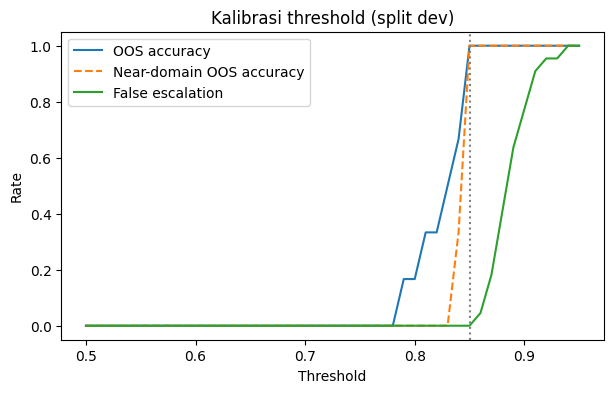

,threshold,oos_acc,near_oos_acc,false_esc,J
35,0.85,1.000000,1.000000,0.000000,1.000000
36,0.86,1.000000,1.000000,0.045455,0.954545
37,0.87,1.000000,1.000000,0.181818,0.818182
34,0.84,0.666667,0.333333,0.000000,0.666667
38,0.88,1.000000,1.000000,0.409091,0.590909
33,0.83,0.500000,0.000000,0.000000,0.500000
39,0.89,1.000000,1.000000,0.636364,0.363636
31,0.81,0.333333,0.000000,0.000000,0.333333


In [24]:
import matplotlib.pyplot as plt

dev = test_set_final[test_set_final['split'] == 'dev']
sw_rows = []
for _, r in dev.iterrows():
    nodes = retriever.retrieve(r['question'])
    sw_rows.append({'oos': r['category'] == 'Out-of-Scope',
                    'oos_type': r.get('oos_type', ''),
                    'top': float(nodes[0].score) if nodes else 0.0})
sw = pd.DataFrame(sw_rows)

print('Rata-rata top-score:')
print(f"  in-scope          : {sw[~sw.oos].top.mean():.3f}  (n={int((~sw.oos).sum())})")
print(f"  OOS easy          : {sw[(sw.oos) & (sw.oos_type == 'easy')].top.mean():.3f}")
print(f"  OOS near-domain   : {sw[(sw.oos) & (sw.oos_type == 'near-domain')].top.mean():.3f}")

res = []
for t in np.arange(0.50, 0.96, 0.01):
    oos_ok  = (sw[sw.oos].top < t).mean()
    near_ok = (sw[(sw.oos) & (sw.oos_type == 'near-domain')].top < t).mean()
    false_e = (sw[~sw.oos].top < t).mean()
    res.append({'threshold': round(float(t), 2), 'oos_acc': oos_ok, 'near_oos_acc': near_ok,
                'false_esc': false_e, 'J': oos_ok - false_e})
sweep = pd.DataFrame(res)

ok = sweep[sweep.oos_acc >= 0.90]
best = ok.sort_values(['false_esc', 'threshold']).iloc[0] if len(ok) else sweep.sort_values('J', ascending=False).iloc[0]
print(f"\nThreshold terpilih: {best.threshold:.2f}  (OOS acc {best.oos_acc:.0%}, near-domain {best.near_oos_acc:.0%}, false esc {best.false_esc:.0%})")

plt.figure(figsize=(7, 4))
plt.plot(sweep.threshold, sweep.oos_acc, label='OOS accuracy')
plt.plot(sweep.threshold, sweep.near_oos_acc, label='Near-domain OOS accuracy', linestyle='--')
plt.plot(sweep.threshold, sweep.false_esc, label='False escalation')
plt.axvline(best.threshold, color='gray', linestyle=':')
plt.xlabel('Threshold'); plt.ylabel('Rate'); plt.legend(); plt.title('Kalibrasi threshold (split dev)')
plt.savefig(f'{BASE_DIR}/threshold_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
display(sweep.sort_values('J', ascending=False).head(8))

In [25]:
# Terapkan threshold terpilih (boleh Anda ubah manual setelah melihat grafik)
SIMILARITY_THRESHOLD = float(best.threshold)
print('SIMILARITY_THRESHOLD =', SIMILARITY_THRESHOLD)

SIMILARITY_THRESHOLD = 0.85


## 15. Jalankan Evaluasi pada Split **test**

In [26]:
EVAL_SPLIT = 'test'     # 'test' (disarankan, untuk laporan) atau 'all'
eval_src = test_set_final if EVAL_SPLIT == 'all' else test_set_final[test_set_final['split'] == EVAL_SPLIT]
print(f'Mengevaluasi {len(eval_src)} soal (split={EVAL_SPLIT}), threshold={SIMILARITY_THRESHOLD:.2f}')

eval_rows = []
for _, row in eval_src.iterrows():
    t0 = time.time()
    res = ask_with_guardrail(row['question'])
    lat = time.time() - t0
    eval_rows.append({
        'id': row['id'], 'question': row['question'], 'ground_truth': row['ground_truth_answer'],
        'category': row['category'], 'oos_type': row.get('oos_type', ''), 'ticket_category': row.get('ticket_category', ''),
        'gt_file': row.get('source_file', ''), 'gt_start': row.get('source_page_start', np.nan),
        'gt_end': row.get('source_page_end', np.nan),
        'answer': res['answer'], 'contexts': res['contexts'], 'retrieved': res['retrieved'],
        'escalate': res['escalate'], 'escalate_reason': res.get('escalate_reason'), 'top_score': res['top_score'], 'latency_sec': round(lat, 2),
    })
    print(f"[{row['id']}] esc={res['escalate']!s:5} top={res['top_score']:.3f} {lat:5.1f}s | {str(row['question'])[:60]}")

eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(f'{BASE_DIR}/eval_results.csv', index=False)
print(f'\nSelesai: {len(eval_df)} soal')

Mengevaluasi 25 soal (split=test), threshold=0.85
[1] esc=False top=0.893   5.3s | Apa yang harus dilakukan untuk mengatasi network bottleneck?
[4] esc=False top=0.875   8.0s | Apa definisi bandwidth dan bagaimana pengukurannya?
[8] esc=False top=0.883   5.2s | Apa fungsi utama dari wireless router?
[9] esc=False top=0.856   4.3s | Apa yang terjadi jika komputer tidak terhubung dengan websit
[10] esc=False top=0.865   5.0s | Apa alternatif dari BGP untuk load balancing internet?
[13] esc=False top=0.915  12.3s | Apa itu Network Bottleneck dan mengapa harus dilakukan troub
[14] esc=False top=0.864   8.3s | Apa fungsi utama modem?
[15] esc=False top=0.877   4.3s | Apa langkah selanjutnya setelah masalah dapat diselesaikan d
[16] esc=False top=0.893   3.6s | Apa yang harus dilakukan pertama kali jika komputer terkena 
[22] esc=False top=0.911   9.0s | Apa perbedaan antara monitor plasma dan monitor LCD?
[23] esc=False top=0.917   5.7s | Apa yang dimaksud dengan primary, extended, dan logi

## 16. Metrik Guardrail, Retrieval (Hit@k, MRR) & Latency

In [27]:
oos_mask = eval_df['category'] == 'Out-of-Scope'
oos_e, in_e = eval_df[oos_mask], eval_df[~oos_mask]

def rate(df, col='escalate'):
    return float(df[col].mean()) if len(df) else float('nan')

guardrail_accuracy    = rate(oos_e)                                          # OOS yang benar dieskalasi
guardrail_acc_easy    = rate(oos_e[oos_e.oos_type == 'easy'])
guardrail_acc_near    = rate(oos_e[oos_e.oos_type == 'near-domain'])
false_escalation_rate = rate(in_e)
avg_latency           = float(eval_df['latency_sec'].mean())

print(f'Guardrail accuracy (semua OOS)   : {guardrail_accuracy:.1%} (n={len(oos_e)})')
print(f'   - easy                        : {guardrail_acc_easy:.1%}')
print(f'   - near-domain (lebih sulit)   : {guardrail_acc_near:.1%}')
print(f'False escalation rate            : {false_escalation_rate:.1%} (n={len(in_e)})')
print(f'Latency rata-rata                : {avg_latency:.2f} detik')
reasons = eval_df['escalate_reason'].fillna('-').value_counts().to_dict()   # [BARU v4]
n_esc_sim = reasons.get('low_similarity', 0); n_esc_llm = reasons.get('not_in_context', 0)
print('Alasan eskalasi (semua soal)     :', reasons)

# ---- Retrieval: tidak bergantung pada LLM-judge ----
ranks = []
for _, r in in_e.iterrows():
    if r['gt_file'] and not pd.isna(r['gt_start']) and not pd.isna(r['gt_end']):
        ranks.append((r['category'], first_hit_rank(r['retrieved'], r['gt_file'], int(r['gt_start']), int(r['gt_end']))))
rk = pd.DataFrame(ranks, columns=['category', 'rank'])
if len(rk):
    hit1    = float((rk['rank'] == 1).mean())
    hit_k   = float(rk['rank'].notna().mean())
    mrr     = float(rk['rank'].map(lambda x: 1 / x if x else 0).mean())
    print(f'\nRetrieval (level halaman, n={len(rk)}): Hit@1={hit1:.1%} | Hit@{TOP_K}={hit_k:.1%} | MRR={mrr:.3f}')
    display(rk.assign(hit=rk['rank'].notna()).groupby('category')['hit'].agg(['mean', 'count']).rename(columns={'mean': f'Hit@{TOP_K}'}))
else:
    hit1 = hit_k = mrr = float('nan')
    print('Tidak ada baris dengan source_file/halaman untuk menghitung Hit@k.')

Guardrail accuracy (semua OOS)   : 100.0% (n=5)
   - easy                        : 100.0%
   - near-domain (lebih sulit)   : 100.0%
False escalation rate            : 5.0% (n=20)
Latency rata-rata                : 4.82 detik
Alasan eskalasi (semua soal)     : {'-': 19, 'low_similarity': 5, 'not_in_context': 1}

Retrieval (level halaman, n=20): Hit@1=75.0% | Hit@4=100.0% | MRR=0.858


,Hit@4,count
category,,
Hardware/Software,1.0,10
Hosting,1.0,1
Network,1.0,9


### Proxy faithfulness leksikal (tanpa LLM-judge)

In [28]:
_WORD = re.compile(r'\w+', re.UNICODE)
LEAK_MARKERS = ['---------------------', 'Jawaban:', 'Pertanyaan:', '<|im_end|>']

def lexical_support(answer, contexts):
    vocab = set(_WORD.findall(' '.join(contexts).lower()))
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+|\n+', str(answer)) if len(s.split()) >= 3]
    scores = []
    for s in sents:
        toks = [w for w in _WORD.findall(s.lower()) if len(w) >= 4 and not w.isdigit()]
        if toks:
            scores.append(float(np.mean([w in vocab for w in toks])))
    if not scores:
        return np.nan, np.nan
    return float(np.mean(scores)), float(np.mean([x >= 0.7 for x in scores]))

grounding_lex_mean = avg_answer_words = leak_rate = float('nan')
ans_df = eval_df[(eval_df['category'] != 'Out-of-Scope') & (eval_df['escalate'] == False)].copy()
if len(ans_df):
    sup = [lexical_support(a, c) for a, c in zip(ans_df['answer'], ans_df['contexts'])]
    ans_df['grounding_lex'] = [s[0] for s in sup]
    ans_df['frac_sent_grounded'] = [s[1] for s in sup]
    ans_df['n_words'] = ans_df['answer'].str.split().str.len()
    ans_df['leak'] = ans_df['answer'].apply(lambda a: any(m in str(a) for m in LEAK_MARKERS))
    grounding_lex_mean = float(ans_df['grounding_lex'].mean())
    avg_answer_words = float(ans_df['n_words'].mean())
    leak_rate = float(ans_df['leak'].mean())
    print(f'Jawaban dinilai                    : {len(ans_df)}')
    print(f'Grounding leksikal (proxy)         : {grounding_lex_mean:.3f}')
    print(f'Kalimat dengan dukungan >= 0.7     : {float(ans_df["frac_sent_grounded"].mean()):.1%}')
    print(f'Rata-rata panjang jawaban (kata)   : {avg_answer_words:.0f}')
    print(f'Jawaban bocor/berulang             : {leak_rate:.1%}')
    display(ans_df.sort_values('grounding_lex').head(5)[['question', 'n_words', 'grounding_lex']])
else:
    print('Tidak ada jawaban non-eskalasi untuk dinilai.')

Jawaban dinilai                    : 19
Grounding leksikal (proxy)         : 0.930
Kalimat dengan dukungan >= 0.7     : 96.3%
Rata-rata panjang jawaban (kata)   : 32
Jawaban bocor/berulang             : 0.0%


,question,n_words,grounding_lex
16,Bagaimana cara memastikan komponen front panel...,51,0.763889
11,Apa dampak jika printer inkjet jarang digunakan?,13,0.833333
5,Apa itu Network Bottleneck dan mengapa harus d...,64,0.868056
2,Apa fungsi utama dari wireless router?,20,0.875000
7,Apa langkah selanjutnya setelah masalah dapat ...,19,0.882353


## 17. Evaluasi Klasifikasi Tiket
Hanya untuk baris yang kolom `ticket_category`-nya terisi (isi manual untuk Hardware/Software saat review).

In [29]:
cls_df = in_e[in_e['ticket_category'].astype(str).isin(CATEGORIES)].copy()
if len(cls_df):
    def _ctx(r):
        return None if r['escalate'] or not len(r['contexts']) else r['contexts'][0]
    cls_df['pred_q']   = cls_df['question'].map(classify_ticket)
    cls_df['pred_ctx'] = cls_df.apply(lambda r: classify_ticket(r['question'], _ctx(r)), axis=1)
    classification_accuracy_q = float((cls_df['pred_q'] == cls_df['ticket_category']).mean())
    classification_accuracy   = float((cls_df['pred_ctx'] == cls_df['ticket_category']).mean())
    print(f'Akurasi klasifikasi (n={len(cls_df)}): tanpa konteks {classification_accuracy_q:.1%} | dengan konteks {classification_accuracy:.1%}')
    print('\nConfusion matrix (dengan konteks):')
    display(pd.crosstab(cls_df['ticket_category'], cls_df['pred_ctx'], rownames=['aktual'], colnames=['prediksi']))
else:
    classification_accuracy = classification_accuracy_q = float('nan')
    print('Kolom ticket_category belum terisi -> evaluasi klasifikasi dilewati.')

Akurasi klasifikasi (n=18): tanpa konteks 88.9% | dengan konteks 88.9%

Confusion matrix (dengan konteks):


prediksi,Hardware,Hosting,Lainnya,Network,Software
aktual,,,,,
Hardware,7,0,0,0,0
Hosting,0,1,0,0,0
Network,1,0,1,7,0
Software,0,0,0,0,1


## 18. RAGAS (LLM-judge open source)

In [30]:
from importlib.metadata import version, PackageNotFoundError
for pkg in ['ragas', 'langchain', 'langchain-core', 'langchain-community', 'langchain-huggingface', 'pydantic', 'numpy']:
    try:
        print(f'{pkg:24s} {version(pkg)}')
    except PackageNotFoundError:
        print(f'{pkg:24s} TIDAK TERPASANG')

from datasets import Dataset
ragas_source_df = eval_df[(eval_df['category'] != 'Out-of-Scope') & (eval_df['escalate'] == False)].reset_index(drop=True)
ragas_coverage = len(ragas_source_df) / max(len(in_e), 1)
print(f'\nBaris dinilai RAGAS: {len(ragas_source_df)} dari {len(in_e)} soal in-scope (coverage {ragas_coverage:.0%})')

ragas_dataset = Dataset.from_dict({
    'question':     ragas_source_df['question'].tolist(),
    'answer':       ragas_source_df['answer'].tolist(),
    'contexts':     ragas_source_df['contexts'].tolist(),
    'ground_truth': ragas_source_df['ground_truth'].tolist(),
})

ragas                    0.1.21
langchain                0.2.16
langchain-core           0.2.43
langchain-community      0.2.16
langchain-huggingface    0.0.3
pydantic                 2.14.1
numpy                    1.26.4

Baris dinilai RAGAS: 19 dari 20 soal in-scope (coverage 95%)


In [31]:
import sys, subprocess
from transformers import pipeline as hf_pipeline
from langchain_huggingface import HuggingFacePipeline, HuggingFaceEmbeddings
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper

JUDGE_BACKEND = 'local'            # 'local' = Qwen yang sama (100% open source) | 'gemini' = judge lebih kuat via API (opsional)
GEMINI_MODEL  = 'gemini-2.5-flash' # cek nama model terbaru di dokumentasi Google bila gagal

if JUDGE_BACKEND == 'gemini':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'langchain-google-genai<2'])
    from google.colab import userdata
    os.environ['GOOGLE_API_KEY'] = userdata.get('GOOGLE_API_KEY')      # simpan di Colab Secrets
    from langchain_google_genai import ChatGoogleGenerativeAI
    ragas_llm = LangchainLLMWrapper(ChatGoogleGenerativeAI(model=GEMINI_MODEL, temperature=0))
    print('Judge: Gemini (eksternal).')
else:
    hf_pipe = hf_pipeline(
        'text-generation', model=llm._model, tokenizer=llm._tokenizer,
        max_new_tokens=1024, temperature=0.1, do_sample=True, top_p=0.9, return_full_text=False,
    )
    ragas_llm = LangchainLLMWrapper(HuggingFacePipeline(pipeline=hf_pipe))
    print('Judge: Qwen lokal (model yang sama dengan generator -> catat sebagai keterbatasan).')

ragas_embeddings = LangchainEmbeddingsWrapper(HuggingFaceEmbeddings(model_name='intfloat/multilingual-e5-base'))
print('Judge LLM dan embedding RAGAS siap.')


Judge: Qwen lokal (model yang sama dengan generator -> catat sebagai keterbatasan).


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Judge LLM dan embedding RAGAS siap.


In [32]:
from ragas import evaluate
from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall
from ragas.run_config import RunConfig

N_EVAL_LIMIT = None      # isi angka (mis. 5) untuk uji cepat
RETRY_PASSES = 2         # ulangi hanya baris yang masih NaN
METRICS = [faithfulness, answer_relevancy, context_precision, context_recall]
eval_dataset = ragas_dataset if N_EVAL_LIMIT is None else ragas_dataset.select(range(min(N_EVAL_LIMIT, len(ragas_dataset))))
run_cfg = RunConfig(timeout=900, max_workers=1, max_retries=2)

ragas_result = evaluate(eval_dataset, metrics=METRICS, llm=ragas_llm, embeddings=ragas_embeddings,
                        run_config=run_cfg, raise_exceptions=False)
print(ragas_result)
ragas_scores_df = ragas_result.to_pandas()
metric_cols = [m for m in ['faithfulness', 'answer_relevancy', 'context_precision', 'context_recall'] if m in ragas_scores_df.columns]

for p in range(RETRY_PASSES):
    bad = [i for i in range(len(ragas_scores_df)) if ragas_scores_df.loc[i, metric_cols].isna().any()]
    if not bad:
        break
    print(f'\nRetry pass {p + 1}: {len(bad)} baris masih ada NaN')
    r2 = evaluate(eval_dataset.select(bad), metrics=METRICS, llm=ragas_llm, embeddings=ragas_embeddings,
                  run_config=run_cfg, raise_exceptions=False).to_pandas()
    for k, i in enumerate(bad):
        for mcol in metric_cols:
            if pd.isna(ragas_scores_df.at[i, mcol]) and pd.notna(r2.at[k, mcol]):
                ragas_scores_df.at[i, mcol] = r2.at[k, mcol]

ragas_scores_df.to_csv(f'{BASE_DIR}/ragas_scores_per_row.csv', index=False)
print(f'\nBaris dinilai: {len(ragas_scores_df)}')
print('Jumlah baris VALID per metrik (sisanya NaN, tidak ikut rata-rata):')
for mcol in metric_cols:
    print(f'  {mcol}: {int(ragas_scores_df[mcol].notna().sum())}/{len(ragas_scores_df)}')
print('\nSkor rata-rata (hanya baris valid):')
for mcol in metric_cols:
    print(f'  {mcol}: {ragas_scores_df[mcol].mean():.3f}')
print('\n5 baris faithfulness terendah (kandidat halusinasi, cek manual):')
display(ragas_scores_df.dropna(subset=['faithfulness']).sort_values('faithfulness').head(5)[['question', 'answer', 'faithfulness']])

Evaluating:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


{'faithfulness': 0.8756, 'answer_relevancy': 0.8920, 'context_precision': 0.8465, 'context_recall': 0.9868}

Baris dinilai: 19
Jumlah baris VALID per metrik (sisanya NaN, tidak ikut rata-rata):
  faithfulness: 19/19
  answer_relevancy: 19/19
  context_precision: 19/19
  context_recall: 19/19

Skor rata-rata (hanya baris valid):
  faithfulness: 0.876
  answer_relevancy: 0.892
  context_precision: 0.846
  context_recall: 0.987

5 baris faithfulness terendah (kandidat halusinasi, cek manual):


,question,answer,faithfulness
9,Apa perbedaan antara monitor plasma dan monito...,1. Monitor plasma menggunakan plasma atau gas ...,0.285714
2,Apa fungsi utama dari wireless router?,1. Router wireless menyediakan akses ke intern...,0.500000
6,Apa fungsi utama modem?,1. Fungsi utama modem adalah mengubah sinyal d...,0.600000
8,Apa yang harus dilakukan pertama kali jika kom...,1. Scan komputer dengan antivirus.\n2. Lakukan...,0.666667
3,Apa yang terjadi jika komputer tidak terhubung...,1. Muncul pesan request time out\n2. Artinya k...,0.750000


### Error analysis faithfulness rendah

In [33]:
# Error analysis: lihat 3 baris faithfulness terendah beserta jawaban dan konteksnya
# Tujuan: memisahkan tiga penyebab -- (a) jawaban menambah fakta di luar konteks (masalah generator),
# (b) konteks tidak memuat jawaban (masalah retrieval), (c) jawaban benar tetapi dinilai salah oleh judge 7B (noise).
low = ragas_scores_df.dropna(subset=['faithfulness']).sort_values('faithfulness').head(3)
for idx, r in low.iterrows():
    row = ragas_dataset[int(idx)]
    print('=' * 90)
    print(f"faithfulness={r['faithfulness']:.2f} | Q: {row['question']}")
    print('JAWABAN:', row['answer'][:700])
    for k, c in enumerate(row['contexts'][:2], 1):
        print(f'--- konteks [{k}] ---')
        print(c[:500])

faithfulness=0.29 | Q: Apa perbedaan antara monitor plasma dan monitor LCD?
JAWABAN: 1. Monitor plasma menggunakan plasma atau gas untuk menghasilkan cahaya, sementara monitor LCD menggunakan lampu neon di belakang kristal cair.
2. Monitor plasma lebih tipis dibandingkan monitor LCD.
3. Monitor plasma memiliki sudut pandang yang lebih luas dibandingkan monitor LCD.
4. Monitor LCD lebih rentan terhadap dead pixel dibandingkan monitor plasma.
5. Monitor plasma memiliki efek flicker, sementara monitor LCD tidak memiliki efek flicker.
--- konteks [1] ---
2. Plasma Display 
Gambar 92. Monitor Plasma 
Monitor plasma merupakan monitor yang disetiap pixel yang berada di layar diterangi oleh 
plasma atau gas seperti lampu neon yang berukuran kecil. Tampilan monitor plasma lebih 
tipis dibandingkan dengan monitor CRT. 
3. LCD Monitor 
Gambar 93. Monitor LCD 
LCD atau Liquid Crystal Display merupakan monitor yang tidak menggunakan tabung. 
Pada jenis monitor ini maka gambar yang dihasilkan memili

## 19. Rangkuman Akhir untuk Laporan

In [34]:
def m(col):
    return float(ragas_scores_df[col].mean()) if 'ragas_scores_df' in globals() and col in ragas_scores_df.columns else None

def nv(col):
    return int(ragas_scores_df[col].notna().sum()) if 'ragas_scores_df' in globals() and col in ragas_scores_df.columns else None

summary_data = {
    'Threshold guardrail': SIMILARITY_THRESHOLD,
    'Split dievaluasi': EVAL_SPLIT,
    'Jumlah soal in-scope': len(in_e),
    'Jumlah soal OOS': len(oos_e),
    'Hit@1': hit1, f'Hit@{TOP_K}': hit_k, 'MRR': mrr,
    'Faithfulness': m('faithfulness'), 'Faithfulness (n valid)': nv('faithfulness'),
    'Answer Relevancy': m('answer_relevancy'), 'Answer Relevancy (n valid)': nv('answer_relevancy'),
    'Context Precision': m('context_precision'), 'Context Precision (n valid)': nv('context_precision'),
    'Context Recall': m('context_recall'), 'Context Recall (n valid)': nv('context_recall'),
    'RAGAS coverage (in-scope tidak dieskalasi)': ragas_coverage,
    'Guardrail Accuracy (semua OOS)': guardrail_accuracy,
    'Guardrail Accuracy (near-domain)': guardrail_acc_near,
    'False Escalation Rate': false_escalation_rate,
    'Akurasi klasifikasi tiket (tanpa konteks)': classification_accuracy_q,
    'Akurasi klasifikasi tiket (dengan konteks)': classification_accuracy,
    'Latency rata-rata (detik)': avg_latency,
    'Grounding leksikal (proxy)': globals().get('grounding_lex_mean'),
    'Rata-rata panjang jawaban (kata)': globals().get('avg_answer_words'),
    'Jawaban bocor/berulang (fraksi)': globals().get('leak_rate'),
    'Eskalasi: similarity rendah (n)': globals().get('n_esc_sim'),
    'Eskalasi: LLM tak menemukan jawaban (n)': globals().get('n_esc_llm'),
}
summary_df = pd.DataFrame(summary_data.items(), columns=['Metrik', 'Skor'])
summary_df.to_csv(f'{BASE_DIR}/evaluation_summary.csv', index=False)
display(summary_df)

from google.colab import files
for p in ['evaluation_summary.csv', 'ragas_scores_per_row.csv', 'eval_results.csv', 'threshold_sweep.png', 'test_set_final_v2.csv']:
    if os.path.exists(f'{BASE_DIR}/{p}'):
        files.download(f'{BASE_DIR}/{p}')

,Metrik,Skor
0,Threshold guardrail,0.85
1,Split dievaluasi,test
2,Jumlah soal in-scope,20
3,Jumlah soal OOS,5
4,Hit@1,0.75
5,Hit@4,1.0
6,MRR,0.858333
7,Faithfulness,0.875564
8,Faithfulness (n valid),19
9,Answer Relevancy,0.891951


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20. Demo UI Gradio

In [39]:
import gradio as gr

def chat_fn(message, history):
    result = ask_with_guardrail(message)
    category = classify_ticket(message)
    log_ticket(message, result['answer'], category, result['escalate'], result['sources'])

    answer = result['answer']
    footer = f"\n\n---\n**Kategori tiket:** {category}"
    if result['sources']:
        src_str = ', '.join([f"{s['file']} (score: {s['score']})" for s in result['sources']])
        footer += f'\n**Sumber:** {src_str}'
    if result['escalate']:
        footer += '\n\n⚠️ **Tiket dieskalasi ke agent manusia.**'

    return answer + footer

demo = gr.ChatInterface(
    fn=chat_fn,
    title='IT Service Desk Assistant',
    description='Tanyakan masalah IT kamu — dijawab berdasarkan dokumen SOP internal.',
)
import inspect, asyncio
import uvicorn.server as _uv
if 'loop_factory' not in inspect.signature(_uv.asyncio_run).parameters:
    _uv.asyncio_run = asyncio.runners.run
try:
    gr.close_all()   # tutup server lama dari percobaan sebelumnya
except Exception:
    pass

demo.launch(share=True)


Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e35ac3995280bd1e48.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Backup Index ChromaDB & Log Tiket

In [40]:
# !zip -r chroma_db_backup.zip /content/chroma_db
# from google.colab import files
# files.download('chroma_db_backup.zip')

if os.path.exists(LOG_FILE):
    log_df = pd.read_csv(LOG_FILE)
    print(f'Total tiket: {len(log_df)} | Dieskalasi: {(log_df["escalate"] == True).mean():.0%}')
    display(log_df['category'].value_counts().rename('jumlah').to_frame())
else:
    print('Belum ada tiket di log.')


Belum ada tiket di log.
